<a href="https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_7_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_7_Neural_Networks.ipynb)

# MAT 422 - Section 3.7: Artificial Neural Networks

**Topics:** Mathematical formulation, Activation functions, Cost function, Backpropagation, Backpropagation algorithm

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(422)


## Mathematical formulation

A neural network is a chain of simple steps. Each layer multiplies its input by a weight matrix, adds a bias, and applies an activation:

$$z^{(1)} = XW^{(1)} + b^{(1)}, \quad a^{(1)} = \tanh(z^{(1)}), \quad z^{(2)} = a^{(1)}W^{(2)} + b^{(2)}, \quad \hat{y} = \sigma(z^{(2)})$$

We use the XOR data set: the output is 1 only when exactly one input is 1. A straight line cannot separate XOR, so we need a hidden layer. The weights start random, so the first predictions are just guesses near 0.5.

After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.

In [2]:
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1 = rng.normal(scale=0.5, size=(2, 3))
b1 = np.zeros((1, 3))
W2 = rng.normal(scale=0.5, size=(3, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

_, hidden, _, output = forward(X)
print("Hidden layer values:")
print(hidden)
print("Initial predicted probabilities:")
print(output)


Hidden layer values:
[[ 0.       0.       0.     ]
 [-0.69724 -0.11969  0.44297]
 [ 0.76367  0.25701  0.32008]
 [ 0.14209  0.14167  0.6683 ]]
Initial predicted probabilities:
[[0.5    ]
 [0.58828]
 [0.41711]
 [0.49511]]


**What this shows:** each row of the hidden layer is one input point turned into 3 new features. The output is one probability per point. Before training, all four guesses are close to 0.5.

### Extension: picture of the network

The diagram below draws the 2-3-1 network. Thicker lines mean larger weights. Blue means a positive weight and red means a negative one.

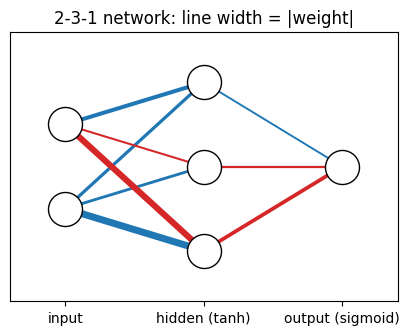

In [3]:
layers = [2, 3, 1]
pos = {}
for L, n in enumerate(layers):
    for i in range(n):
        pos[(L, i)] = (L, i - (n - 1) / 2)

plt.figure(figsize=(5, 3.5))
for L, W in enumerate([W1, W2]):
    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            (x0, y0), (x1, y1) = pos[(L, i)], pos[(L + 1, j)]
            plt.plot([x0, x1], [y0, y1], color="tab:blue" if W[i, j] > 0 else "tab:red",
                     linewidth=1 + 4 * abs(W[i, j]))
for (L, i), (x, yy) in pos.items():
    plt.scatter(x, yy, s=600, color="white", edgecolor="black", zorder=3)
plt.xlim(-0.4, 2.4)
plt.ylim(-1.6, 1.6)
plt.xticks([0, 1, 2], ["input", "hidden (tanh)", "output (sigmoid)"])
plt.yticks([])
plt.title("2-3-1 network: line width = |weight|")
plt.show()

**Interpretation:** every input connects to every hidden neuron, and every hidden neuron connects to the output. Training will change these line widths and colors.

## Activation functions

An activation function bends the output of each neuron. Without it, stacking layers would still give only a straight-line (linear) model.

- **Sigmoid** squashes any number into (0, 1), so it works well for probabilities.
- **ReLU** keeps positive values and sets negatives to 0. It is simple and fast.

After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.

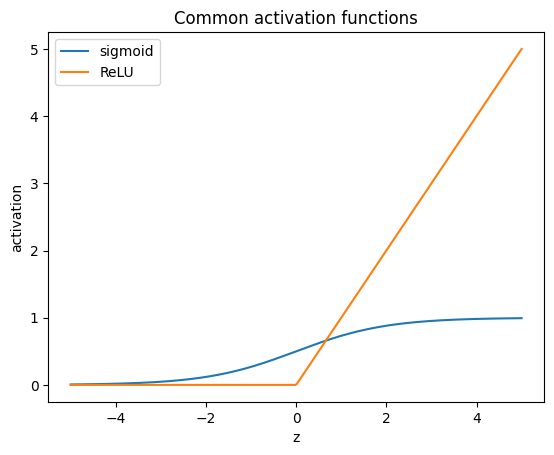

In [4]:
def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 300)
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Common activation functions")
plt.legend()
plt.show()


**What this shows:** sigmoid is a smooth S-curve between 0 and 1. ReLU is flat at 0 for negative inputs and a straight line for positive inputs.

### Extension: tanh and the activation slopes

Our hidden layer uses **tanh**, so we add it here. We also plot the **derivatives** (slopes), because backpropagation multiplies by these slopes.

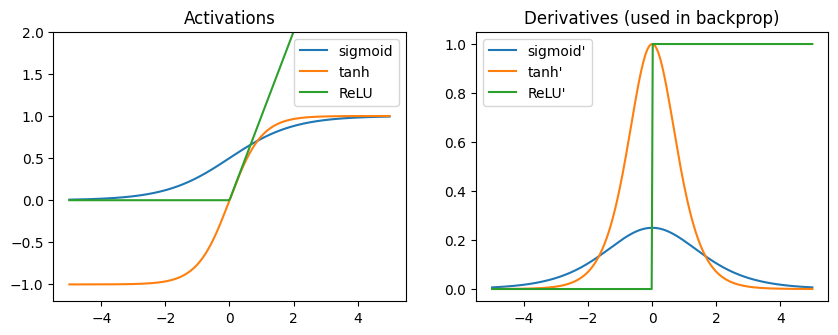

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(z, sigmoid(z), label="sigmoid")
ax[0].plot(z, np.tanh(z), label="tanh")
ax[0].plot(z, relu(z), label="ReLU")
ax[0].set_ylim(-1.2, 2)
ax[0].set_title("Activations")
ax[0].legend()

ax[1].plot(z, sigmoid(z) * (1 - sigmoid(z)), label="sigmoid'")
ax[1].plot(z, 1 - np.tanh(z)**2, label="tanh'")
ax[1].plot(z, (z > 0).astype(float), label="ReLU'")
ax[1].set_title("Derivatives (used in backprop)")
ax[1].legend()
plt.show()

**Interpretation:** the sigmoid and tanh slopes are near 0 for large $|z|$. Then the gradient becomes tiny and learning slows down (the *vanishing gradient* problem). ReLU keeps a slope of 1 for every positive input.

## Cost function

The cost function gives one number that says how wrong the predictions are. For 0/1 targets we use **binary cross-entropy**:

$$J = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log \hat{y}_i + (1-y_i)\log(1-\hat{y}_i)\right]$$

Smaller is better. A random network predicting about 0.5 for every point gives a cost near $\log 2 \approx 0.693$.

After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.

In [6]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    return -np.mean(y_true*np.log(y_prob + eps) + (1-y_true)*np.log(1-y_prob + eps))

_, _, _, output = forward(X)
print("Initial binary cross-entropy =", binary_cross_entropy(y, output))
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())


Initial binary cross-entropy = 0.6953799446372811
Target values: [0. 1. 1. 0.]
Initial predicted probabilities: [0.5     0.58828 0.41711 0.49511]


**What this shows:** the starting cost is about 0.69 because the untrained network guesses about 0.5 for every point.

### Extension: how the cost punishes wrong guesses

We plot the cost for a single point as the predicted probability changes, once for a target of 1 and once for a target of 0.

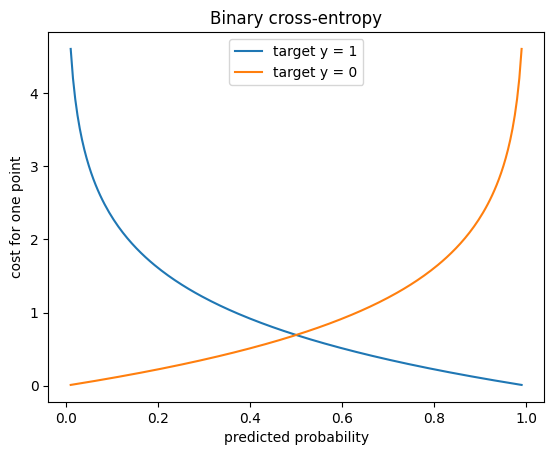

In [7]:
p = np.linspace(0.01, 0.99, 200)
plt.plot(p, -np.log(p), label="target y = 1")
plt.plot(p, -np.log(1 - p), label="target y = 0")
plt.xlabel("predicted probability")
plt.ylabel("cost for one point")
plt.title("Binary cross-entropy")
plt.legend()
plt.show()

**Interpretation:** a correct and confident guess costs almost nothing. A wrong and confident guess costs a lot, and the curve shoots up. This pushes the network to avoid confident mistakes.

## Backpropagation

Backpropagation uses the chain rule to find how the cost changes when each weight changes. It starts with the output error $\hat{y} - y$ and passes it backward, layer by layer. Each gradient has the same shape as its weight, which the printed shapes confirm.

After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.

In [8]:
z1, a1, z2, a2 = forward(X)
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("Backpropagation sends the output error backward through W2 and the tanh derivative.")


dW2 shape: (3, 1)
db2 shape: (1, 1)
dW1 shape: (2, 3)
db1 shape: (1, 3)
Backpropagation sends the output error backward through W2 and the tanh derivative.


**What this shows:** each gradient has the same shape as the weight it belongs to, so we can subtract it from that weight directly.

### Extension: check the gradients numerically

We can check backpropagation without calculus. Nudge one weight by a tiny amount $h$ and measure how much the cost changes:

$$\frac{\partial J}{\partial w} \approx \frac{J(w+h) - J(w-h)}{2h}$$

If backpropagation is correct, the two bars for each weight should match.

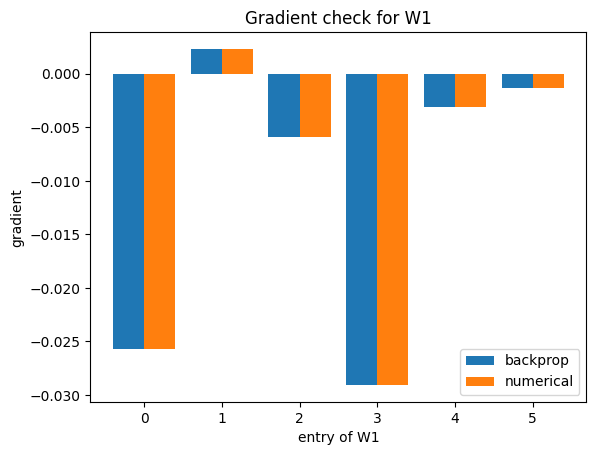

Largest difference: 5.984340453735193e-11


In [9]:
h = 1e-5
numeric = np.zeros_like(W1)
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        W1[i, j] += h
        cost_plus = binary_cross_entropy(y, forward(X)[3])
        W1[i, j] -= 2 * h
        cost_minus = binary_cross_entropy(y, forward(X)[3])
        W1[i, j] += h  # put the weight back
        numeric[i, j] = (cost_plus - cost_minus) / (2 * h)

idx = np.arange(W1.size)
plt.bar(idx - 0.2, dW1.ravel(), width=0.4, label="backprop")
plt.bar(idx + 0.2, numeric.ravel(), width=0.4, label="numerical")
plt.xlabel("entry of W1")
plt.ylabel("gradient")
plt.title("Gradient check for W1")
plt.legend()
plt.show()
print("Largest difference:", np.max(np.abs(dW1 - numeric)))

**Interpretation:** the bars match and the largest difference is tiny, so our chain-rule formulas are correct.

## Backpropagation algorithm

The full algorithm repeats four steps many times:

1. **Forward pass:** compute the predictions.
2. **Cost:** measure the error.
3. **Backward pass:** compute the gradients with backpropagation.
4. **Update:** move each weight a small step against its gradient, $W \leftarrow W - \eta\,\frac{\partial J}{\partial W}$.

If it works, the loss curve should go down and the network should learn XOR.

After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.

Final probabilities:
[[0.00031]
 [0.9969 ]
 [0.99683]
 [0.00411]]
Final predictions: [0 1 1 0]


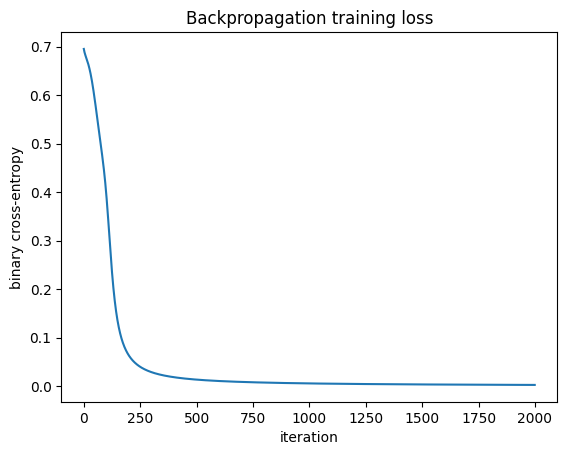

In [10]:
learning_rate = 0.5
losses = []
for step in range(2000):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    losses.append(binary_cross_entropy(y, a2))

    dz2 = (a2 - y) / len(X)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - np.tanh(z1)**2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

_, _, _, final_output = forward(X)
print("Final probabilities:")
print(final_output)
print("Final predictions:", (final_output > 0.5).astype(int).ravel())

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.show()


**What this shows:** the loss drops as training goes on, and the final predictions should match the XOR targets 0, 1, 1, 0.

### Extension: see what the network learned

We color every point of the plane by the trained network's predicted probability. The four XOR points are drawn on top.

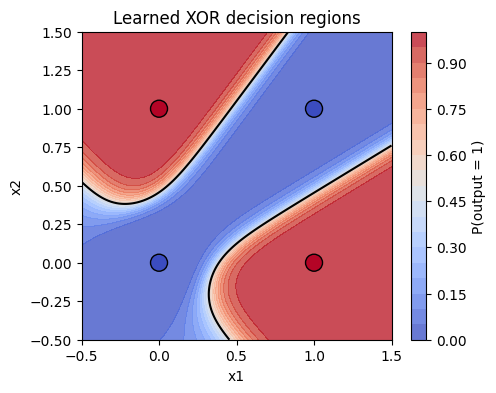

In [11]:
g = np.linspace(-0.5, 1.5, 200)
gx, gy = np.meshgrid(g, g)
grid = np.column_stack([gx.ravel(), gy.ravel()])
prob = forward(grid)[3].reshape(gx.shape)

plt.figure(figsize=(5, 4))
plt.contourf(gx, gy, prob, levels=20, cmap="coolwarm", alpha=0.8)
plt.colorbar(label="P(output = 1)")
plt.contour(gx, gy, prob, levels=[0.5], colors="black")
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", edgecolor="black", s=150)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Learned XOR decision regions")
plt.show()

**Interpretation:** the black line is where the probability is 0.5. It is curved, not straight, so the hidden layer lets the network solve XOR, which a single straight line cannot do.

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
